In [1]:
import pandas as pd
import numpy as np
import geopandas as gpd
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import IsolationForest
from sklearn.metrics import silhouette_score

import joblib
import os

print("All libraries imported successfully!")

All libraries imported successfully!


In [13]:
import geopandas as gpd

water = gpd.read_file(
    "../data/processed/patiala_water_drainage_cleaned.geojson"
)

roads = gpd.read_file(
    "../data/processed/patiala_roads_cleaned.geojson"
)

buildings = gpd.read_file(
    "../data/processed/patiala_buildings_cleaned.geojson"
)

print("All datasets loaded successfully!")

All datasets loaded successfully!


In [14]:
water_utm = water.to_crs(epsg=32643)
roads_utm = roads.to_crs(epsg=32643)
buildings_utm = buildings.to_crs(epsg=32643)

print("Coordinate conversion completed!")

Coordinate conversion completed!


In [2]:
# Load the processed grid dataset
grid_features = gpd.read_file(
    "../data/processed/patiala_grid_features.geojson"
)

print("Dataset loaded successfully!")

print("Dataset shape:", grid_features.shape)

print("\nAvailable columns:")
print(grid_features.columns.tolist())

print("\nFirst five records:")
display(grid_features.head())

Dataset loaded successfully!
Dataset shape: (1216, 16)

Available columns:
['grid_id', 'building_count', 'building_area_m2', 'road_length_m', 'drain_length_m', 'ditch_length_m', 'canal_length_m', 'stream_length_m', 'building_density_km2', 'road_density_km_km2', 'drainage_density_km_km2', 'building_coverage_pct', 'high_building_density', 'no_mapped_drain', 'drainage_screening_flag', 'geometry']

First five records:


,grid_id,building_count,building_area_m2,road_length_m,drain_length_m,ditch_length_m,canal_length_m,stream_length_m,building_density_km2,road_density_km_km2,drainage_density_km_km2,building_coverage_pct,high_building_density,no_mapped_drain,drainage_screening_flag,geometry
0,1,0.0,0.0,0.0,0.0,0.0,0.0,711.873412,0.0,0.0,0.0,0.0,True,True,True,"POLYGON ((628480.466 3346660.54, 628480.466 33..."
1,2,0.0,0.0,0.0,0.0,0.0,0.0,341.659832,0.0,0.0,0.0,0.0,True,True,True,"POLYGON ((628480.466 3347160.54, 628480.466 33..."
2,3,0.0,0.0,0.0,0.0,0.0,0.0,0.000000,0.0,0.0,0.0,0.0,True,True,True,"POLYGON ((628480.466 3347660.54, 628480.466 33..."
3,4,0.0,0.0,0.0,0.0,0.0,0.0,0.000000,0.0,0.0,0.0,0.0,True,True,True,"POLYGON ((628480.466 3348160.54, 628480.466 33..."
4,5,0.0,0.0,0.0,0.0,0.0,0.0,0.000000,0.0,0.0,0.0,0.0,True,True,True,"POLYGON ((628480.466 3348660.54, 628480.466 33..."


In [3]:
print("Missing values:")
print(grid_features.isnull().sum())

print("\nDataset information:")
grid_features.info()

print("\nStatistical summary:")
display(grid_features.describe())

Missing values:
grid_id                    0
building_count             0
building_area_m2           0
road_length_m              0
drain_length_m             0
ditch_length_m             0
canal_length_m             0
stream_length_m            0
building_density_km2       0
road_density_km_km2        0
drainage_density_km_km2    0
building_coverage_pct      0
high_building_density      0
no_mapped_drain            0
drainage_screening_flag    0
geometry                   0
dtype: int64

Dataset information:
<class 'geopandas.geodataframe.GeoDataFrame'>
RangeIndex: 1216 entries, 0 to 1215
Data columns (total 16 columns):
 #   Column                   Non-Null Count  Dtype   
---  ------                   --------------  -----   
 0   grid_id                  1216 non-null   int32   
 1   building_count           1216 non-null   float64 
 2   building_area_m2         1216 non-null   float64 
 3   road_length_m            1216 non-null   float64 
 4   drain_length_m           1216 non-n

,grid_id,building_count,building_area_m2,road_length_m,drain_length_m,ditch_length_m,canal_length_m,stream_length_m,building_density_km2,road_density_km_km2,drainage_density_km_km2,building_coverage_pct
count,1216.000000,1216.000000,1216.000000,1216.000000,1216.000000,1216.000000,1216.000000,1216.000000,1216.000000,1216.000000,1216.000000,1216.000000
mean,608.500000,4.561678,1736.969005,1308.591031,8.645132,3.742731,6.448466,24.315088,18.246711,5.234364,0.034581,0.694788
std,351.173272,31.730415,9166.522199,2203.939598,64.372007,42.005792,54.544082,110.749475,126.921660,8.815758,0.257488,3.666609
min,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,304.750000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
50%,608.500000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
75%,912.250000,0.000000,0.000000,2013.486510,0.000000,0.000000,0.000000,0.000000,0.000000,8.053946,0.000000,0.000000
max,1216.000000,584.000000,120350.330000,8629.158154,695.499776,509.090338,624.103264,1148.733473,2336.000000,34.516633,2.781999,48.140132


In [4]:
# Features used for drainage anomaly detection

features = [
    "building_count",
    "building_area_m2",
    "road_length_m",
    "drain_length_m",
    "ditch_length_m",
    "canal_length_m",
    "stream_length_m"
]

# Check whether all required columns exist
missing_columns = [
    col for col in features
    if col not in grid_features.columns
]

if missing_columns:
    raise ValueError(f"Missing columns: {missing_columns}")

X = grid_features[features].copy()

print("Selected features:")
print(X.columns.tolist())

print("\nFeature matrix shape:", X.shape)
display(X.head())

Selected features:
['building_count', 'building_area_m2', 'road_length_m', 'drain_length_m', 'ditch_length_m', 'canal_length_m', 'stream_length_m']

Feature matrix shape: (1216, 7)


,building_count,building_area_m2,road_length_m,drain_length_m,ditch_length_m,canal_length_m,stream_length_m
0,0.0,0.0,0.0,0.0,0.0,0.0,711.873412
1,0.0,0.0,0.0,0.0,0.0,0.0,341.659832
2,0.0,0.0,0.0,0.0,0.0,0.0,0.000000
3,0.0,0.0,0.0,0.0,0.0,0.0,0.000000
4,0.0,0.0,0.0,0.0,0.0,0.0,0.000000


In [5]:
# Replace infinite values with NaN
X = X.replace([np.inf, -np.inf], np.nan)

# Fill missing values with zero
X = X.fillna(0)

# Check for negative values
print("Negative values:")
print((X < 0).sum())

print("\nMissing values after cleaning:")
print(X.isnull().sum())

Negative values:
building_count      0
building_area_m2    0
road_length_m       0
drain_length_m      0
ditch_length_m      0
canal_length_m      0
stream_length_m     0
dtype: int64

Missing values after cleaning:
building_count      0
building_area_m2    0
road_length_m       0
drain_length_m      0
ditch_length_m      0
canal_length_m      0
stream_length_m     0
dtype: int64


In [6]:
# Apply log transformation
X_log = np.log1p(X)

print("Log transformation completed!")

display(X_log.head())

Log transformation completed!


,building_count,building_area_m2,road_length_m,drain_length_m,ditch_length_m,canal_length_m,stream_length_m
0,0.0,0.0,0.0,0.0,0.0,0.0,6.569304
1,0.0,0.0,0.0,0.0,0.0,0.0,5.836738
2,0.0,0.0,0.0,0.0,0.0,0.0,0.000000
3,0.0,0.0,0.0,0.0,0.0,0.0,0.000000
4,0.0,0.0,0.0,0.0,0.0,0.0,0.000000


In [7]:
scaler = StandardScaler()

X_scaled = scaler.fit_transform(X_log)

print("Feature scaling completed!")

print("Scaled dataset shape:", X_scaled.shape)

print("\nScaled feature means:")
print(X_scaled.mean(axis=0).round(3))

print("\nScaled feature standard deviations:")
print(X_scaled.std(axis=0).round(3))

Feature scaling completed!
Scaled dataset shape: (1216, 7)

Scaled feature means:
[-0. -0. -0. -0. -0.  0.  0.]

Scaled feature standard deviations:
[1. 1. 1. 1. 1. 1. 1.]


In [8]:
model = IsolationForest(
    n_estimators=100,
    contamination=0.05,
    random_state=42
)

# Train the model and predict anomalies
predictions = model.fit_predict(X_scaled)

# Store predictions
grid_features["anomaly_prediction"] = predictions

# Convert predictions into readable labels
grid_features["anomaly_status"] = (
    grid_features["anomaly_prediction"]
    .map({
        1: "Normal",
        -1: "Anomaly"
    })
)

print("Isolation Forest training completed!")

print("\nPrediction distribution:")
print(grid_features["anomaly_status"].value_counts())

Isolation Forest training completed!

Prediction distribution:
anomaly_status
Normal     1155
Anomaly      61
Name: count, dtype: int64


In [9]:
grid_features["anomaly_score"] = (
    model.decision_function(X_scaled)
)

# Sort from most unusual to least unusual
anomaly_results = grid_features.sort_values(
    by="anomaly_score",
    ascending=True
)

print("Top 10 unusual grid cells:")

display(
    anomaly_results[
        [
            "grid_id",
            "anomaly_status",
            "anomaly_score",
            "building_count",
            "road_length_m",
            "drain_length_m"
        ]
    ].head(10)
)

Top 10 unusual grid cells:


,grid_id,anomaly_status,anomaly_score,building_count,road_length_m,drain_length_m
510,511,Anomaly,-0.120851,122.0,6531.288845,0.000000
548,549,Anomaly,-0.118361,115.0,6480.824622,0.000000
509,510,Anomaly,-0.104456,116.0,6888.375724,0.000000
433,434,Anomaly,-0.103025,98.0,5060.023985,0.000000
471,472,Anomaly,-0.102877,38.0,3332.884282,0.000000
394,395,Anomaly,-0.087729,19.0,1875.659815,0.000000
549,550,Anomaly,-0.085866,25.0,5292.737885,0.000000
137,138,Anomaly,-0.084091,0.0,3453.914677,551.182542
547,548,Anomaly,-0.073580,92.0,5100.878802,0.000000
356,357,Anomaly,-0.067404,2.0,3663.633939,0.000000


In [10]:
print("Original feature statistics:")

display(X.describe())

print("\nNumber of non-zero values:")

print((X > 0).sum())

print("\nTotal grid cells:", len(X))

Original feature statistics:


,building_count,building_area_m2,road_length_m,drain_length_m,ditch_length_m,canal_length_m,stream_length_m
count,1216.000000,1216.000000,1216.000000,1216.000000,1216.000000,1216.000000,1216.000000
mean,4.561678,1736.969005,1308.591031,8.645132,3.742731,6.448466,24.315088
std,31.730415,9166.522199,2203.939598,64.372007,42.005792,54.544082,110.749475
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
50%,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
75%,0.000000,0.000000,2013.486510,0.000000,0.000000,0.000000,0.000000
max,584.000000,120350.330000,8629.158154,695.499776,509.090338,624.103264,1148.733473



Number of non-zero values:
building_count      156
building_area_m2    156
road_length_m       460
drain_length_m       25
ditch_length_m       10
canal_length_m       20
stream_length_m      68
dtype: int64

Total grid cells: 1216


In [16]:
print("Total buildings:", len(buildings_utm))
print("Total roads:", len(roads_utm))
print("Total water features:", len(water_utm))
print("Total grid cells:", len(grid_features))

Total buildings: 5547
Total roads: 8609
Total water features: 11
Total grid cells: 1216


In [12]:
print("Cells with buildings:")
print((X["building_count"] > 0).sum())

print("\nCells with roads:")
print((X["road_length_m"] > 0).sum())

print("\nCells with mapped drains:")
print((X["drain_length_m"] > 0).sum())

print("\nCells with streams:")
print((X["stream_length_m"] > 0).sum())

Cells with buildings:
156

Cells with roads:
460

Cells with mapped drains:
25

Cells with streams:
68


In [17]:
print("Feature distribution:")

display(X.describe().T)

print("\nPercentage of grid cells with mapped features:")

print(
    ((X > 0).sum() / len(X) * 100).round(2)
)

Feature distribution:


,count,mean,std,min,25%,50%,75%,max
building_count,1216.0,4.561678,31.730415,0.0,0.0,0.0,0.00000,584.000000
building_area_m2,1216.0,1736.969005,9166.522199,0.0,0.0,0.0,0.00000,120350.330000
road_length_m,1216.0,1308.591031,2203.939598,0.0,0.0,0.0,2013.48651,8629.158154
drain_length_m,1216.0,8.645132,64.372007,0.0,0.0,0.0,0.00000,695.499776
ditch_length_m,1216.0,3.742731,42.005792,0.0,0.0,0.0,0.00000,509.090338
canal_length_m,1216.0,6.448466,54.544082,0.0,0.0,0.0,0.00000,624.103264
stream_length_m,1216.0,24.315088,110.749475,0.0,0.0,0.0,0.00000,1148.733473



Percentage of grid cells with mapped features:
building_count      12.83
building_area_m2    12.83
road_length_m       37.83
drain_length_m       2.06
ditch_length_m       0.82
canal_length_m       1.64
stream_length_m      5.59
dtype: float64


In [18]:
active_mask = (
    (X["building_count"] > 0) |
    (X["road_length_m"] > 0)
)

X_active = X.loc[active_mask].copy()

print("Total grid cells:", len(X))
print("Active grid cells:", len(X_active))
print("Empty grid cells:", len(X) - len(X_active))

print("\nActive feature summary:")
display(X_active.describe().T)

Total grid cells: 1216
Active grid cells: 460
Empty grid cells: 756

Active feature summary:


,count,mean,std,min,25%,50%,75%,max
building_count,460.0,12.058696,50.739615,0.000000,0.000000,0.000000,2.00000,584.000000
building_area_m2,460.0,4591.639804,14466.626515,0.000000,0.000000,0.000000,782.00750,120350.330000
road_length_m,460.0,3459.231942,2324.202354,2.737606,1082.973027,3724.526097,5278.93735,8629.158154
drain_length_m,460.0,21.780239,101.855326,0.000000,0.000000,0.000000,0.00000,695.499776
ditch_length_m,460.0,9.893828,67.894839,0.000000,0.000000,0.000000,0.00000,509.090338
canal_length_m,460.0,17.046379,87.716024,0.000000,0.000000,0.000000,0.00000,624.103264
stream_length_m,460.0,40.433074,135.135766,0.000000,0.000000,0.000000,0.00000,752.553186


In [19]:
# Check how many unique values each feature contains

print("Unique values in each feature:\n")

print(X_active.nunique())

print("\nFeatures with zero variation:")

print(
    X_active.columns[
        X_active.nunique() <= 1
    ].tolist()
)

Unique values in each feature:

building_count       56
building_area_m2    157
road_length_m       460
drain_length_m       24
ditch_length_m       11
canal_length_m       21
stream_length_m      45
dtype: int64

Features with zero variation:
[]


In [21]:
# Remove features with no variation
constant_features = X_active.columns[
    X_active.nunique() <= 1
].tolist()

X_model = X_active.drop(
    columns=constant_features
).copy()

print("Removed features:", constant_features)
print("Features used:", X_model.columns.tolist())

# Log transformation
X_model_log = np.log1p(X_model)

# Standardisation
scaler = StandardScaler()

X_active_scaled = scaler.fit_transform(X_model_log)

print("\nScaling completed!")
print("Training data shape:", X_active_scaled.shape)

Removed features: []
Features used: ['building_count', 'building_area_m2', 'road_length_m', 'drain_length_m', 'ditch_length_m', 'canal_length_m', 'stream_length_m']

Scaling completed!
Training data shape: (460, 7)


In [22]:
model = IsolationForest(
    n_estimators=100,
    contamination=0.05,
    random_state=42
)

predictions = model.fit_predict(X_active_scaled)

# Store predictions separately from the original dataset
results = grid_features.loc[X_active.index].copy()

results["anomaly_prediction"] = predictions

results["anomaly_status"] = results[
    "anomaly_prediction"
].map({
    1: "Normal",
    -1: "Anomaly"
})

results["anomaly_score"] = model.decision_function(
    X_active_scaled
)

print("Model training completed!")

print("\nPrediction distribution:")
print(results["anomaly_status"].value_counts())

Model training completed!

Prediction distribution:
anomaly_status
Normal     437
Anomaly     23
Name: count, dtype: int64


In [23]:
top_anomalies = results.sort_values(
    by="anomaly_score",
    ascending=True
)

display(
    top_anomalies[
        [
            "grid_id",
            "anomaly_status",
            "anomaly_score",
            "building_count",
            "road_length_m",
            "drain_length_m"
        ]
    ].head(10)
)

,grid_id,anomaly_status,anomaly_score,building_count,road_length_m,drain_length_m
137,138,Anomaly,-0.086703,0.0,3453.914677,551.182542
510,511,Anomaly,-0.056745,122.0,6531.288845,0.000000
509,510,Anomaly,-0.054226,116.0,6888.375724,0.000000
548,549,Anomaly,-0.050940,115.0,6480.824622,0.000000
433,434,Anomaly,-0.036923,98.0,5060.023985,0.000000
471,472,Anomaly,-0.032290,38.0,3332.884282,0.000000
213,214,Anomaly,-0.030972,9.0,5688.888998,0.000000
547,548,Anomaly,-0.024651,92.0,5100.878802,0.000000
394,395,Anomaly,-0.019660,19.0,1875.659815,0.000000
403,404,Anomaly,-0.018583,1.0,3603.608195,0.000000


In [24]:
print("Anomaly distribution:")
print(results["anomaly_status"].value_counts())

print("\nAnomaly percentage:")
print(
    results["anomaly_status"]
    .value_counts(normalize=True) * 100
)

Anomaly distribution:
anomaly_status
Normal     437
Anomaly     23
Name: count, dtype: int64

Anomaly percentage:
anomaly_status
Normal     95.0
Anomaly     5.0
Name: proportion, dtype: float64


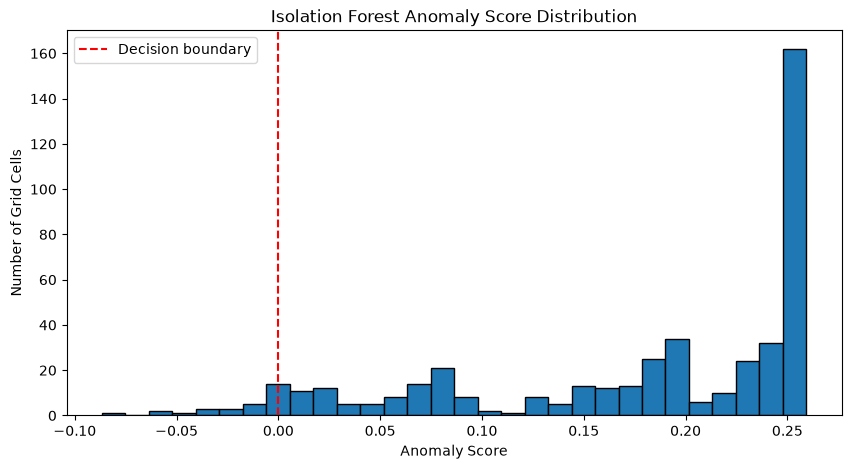

In [25]:
plt.figure(figsize=(10, 5))

plt.hist(
    results["anomaly_score"],
    bins=30,
    edgecolor="black"
)

plt.axvline(
    0,
    color="red",
    linestyle="--",
    label="Decision boundary"
)

plt.xlabel("Anomaly Score")
plt.ylabel("Number of Grid Cells")
plt.title("Isolation Forest Anomaly Score Distribution")
plt.legend()

plt.show()

In [26]:
comparison = results.groupby(
    "anomaly_status"
)[
    [
        "building_count",
        "road_length_m",
        "drain_length_m",
        "ditch_length_m",
        "canal_length_m",
        "stream_length_m"
    ]
].mean()

display(comparison)

,building_count,road_length_m,drain_length_m,ditch_length_m,canal_length_m,stream_length_m
anomaly_status,,,,,,
Anomaly,32.913043,4406.969088,61.818549,153.955155,188.73550,93.108788
Normal,10.961098,3409.351039,19.672959,2.311653,8.01011,37.660668


In [27]:
import os
import joblib

os.makedirs("../models", exist_ok=True)

joblib.dump(
    model,
    "../models/drainage_isolation_forest.pkl"
)

joblib.dump(
    scaler,
    "../models/drainage_scaler.pkl"
)

joblib.dump(
    list(X_model.columns),
    "../models/drainage_feature_columns.pkl"
)

print("Model, scaler and feature list saved successfully!")

Model, scaler and feature list saved successfully!


In [28]:
final_results = results.copy()

def classify_anomaly(row):

    if row["anomaly_status"] == "Anomaly":
        if (
            row["building_count"] > 0
            and row["drain_length_m"] == 0
        ):
            return "High Investigation Priority"

        elif row["drain_length_m"] > 0:
            return "Drainage Network Review"

        else:
            return "Infrastructure Pattern Review"

    return "Normal"

final_results["investigation_category"] = (
    final_results.apply(classify_anomaly, axis=1)
)

print("Investigation categories created!")

print(
    final_results["investigation_category"].value_counts()
)

Investigation categories created!
investigation_category
Normal                           437
High Investigation Priority       16
Infrastructure Pattern Review      4
Drainage Network Review            3
Name: count, dtype: int64


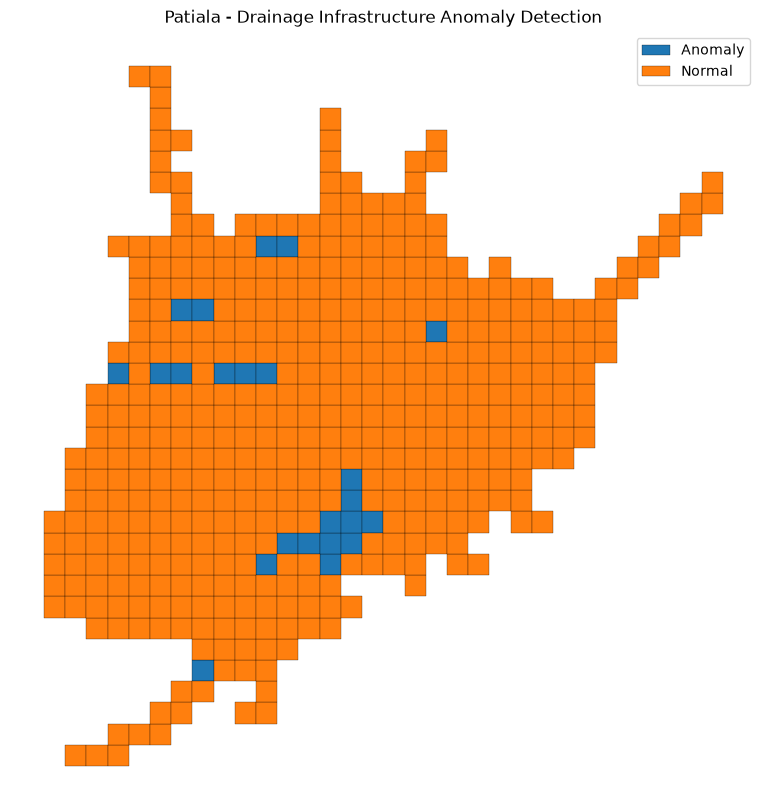

In [29]:
fig, ax = plt.subplots(figsize=(12, 10))

final_results.plot(
    column="anomaly_status",
    categorical=True,
    legend=True,
    ax=ax,
    edgecolor="black",
    linewidth=0.2
)

ax.set_title(
    "Patiala - Drainage Infrastructure Anomaly Detection"
)

ax.set_axis_off()

plt.show()

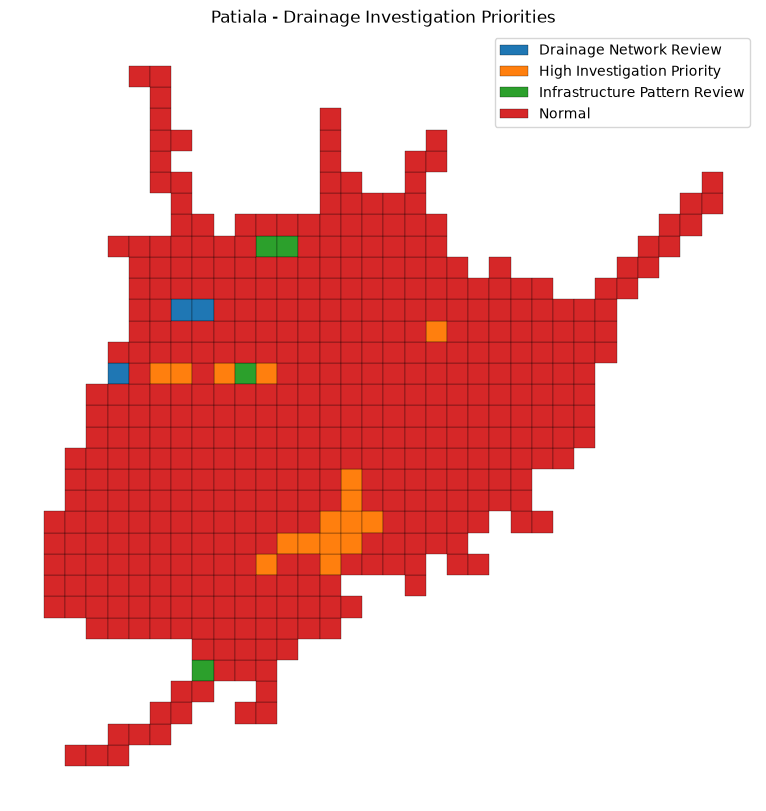

In [30]:
fig, ax = plt.subplots(figsize=(12, 10))

final_results.plot(
    column="investigation_category",
    categorical=True,
    legend=True,
    ax=ax,
    edgecolor="black",
    linewidth=0.2
)

ax.set_title("Patiala - Drainage Investigation Priorities")

ax.set_axis_off()

plt.show()

In [31]:
import os

os.makedirs("../data/processed", exist_ok=True)

# Save geographical results
final_results.to_file(
    "../data/processed/drainage_anomaly_results.geojson",
    driver="GeoJSON"
)

# Save tabular results
final_results.drop(
    columns="geometry"
).to_csv(
    "../data/processed/drainage_anomaly_results.csv",
    index=False
)

print("Final drainage results saved successfully!")

Final drainage results saved successfully!


In [32]:
print("DRAINAGE MODEL SUMMARY")

print("\nTotal active grid cells:", len(final_results))

print(
    "Anomalous cells:",
    (final_results["anomaly_status"] == "Anomaly").sum()
)

print(
    "Normal cells:",
    (final_results["anomaly_status"] == "Normal").sum()
)

print("\nInvestigation categories:")

print(
    final_results["investigation_category"].value_counts()
)

DRAINAGE MODEL SUMMARY

Total active grid cells: 460
Anomalous cells: 23
Normal cells: 437

Investigation categories:
investigation_category
Normal                           437
High Investigation Priority       16
Infrastructure Pattern Review      4
Drainage Network Review            3
Name: count, dtype: int64


In [33]:
# Select high-priority investigation areas

high_priority = final_results[
    final_results["investigation_category"]
    == "High Investigation Priority"
].copy()

print("Total high-priority areas:", len(high_priority))

display(
    high_priority[
        [
            "grid_id",
            "building_count",
            "building_area_m2",
            "road_length_m",
            "drain_length_m",
            "anomaly_score"
        ]
    ].sort_values(
        by="building_count",
        ascending=False
    ).head(20)
)

Total high-priority areas: 16


,grid_id,building_count,building_area_m2,road_length_m,drain_length_m,anomaly_score
510,511,122.0,113049.93,6531.288845,0.0,-0.056745
509,510,116.0,74567.88,6888.375724,0.0,-0.054226
548,549,115.0,87484.93,6480.824622,0.0,-0.050940
433,434,98.0,34968.18,5060.023985,0.0,-0.036923
547,548,92.0,49177.18,5100.878802,0.0,-0.024651
508,509,74.0,39635.96,3834.135989,0.0,-0.000235
471,472,38.0,48438.20,3332.884282,0.0,-0.032290
709,710,26.0,20386.13,2264.472691,0.0,-0.002893
549,550,25.0,17853.81,5292.737885,0.0,-0.014910
394,395,19.0,12752.07,1875.659815,0.0,-0.019660


In [34]:
def recommend_drainage_improvement(row):

    recommendations = []
    reasons = []

    # Check mapped drainage availability
    if row["drain_length_m"] == 0:
        recommendations.append(
            "Conduct field inspection to verify whether "
            "a drainage network exists."
        )
        reasons.append(
            "No drain is mapped in the available dataset."
        )

    # Check building concentration
    if row["building_count"] >= 50:
        recommendations.append(
            "Assess stormwater drainage capacity "
            "for the built-up area."
        )
        reasons.append(
            "High mapped building count."
        )

    elif row["building_count"] > 0:
        recommendations.append(
            "Survey local stormwater flow paths "
            "and drainage connectivity."
        )
        reasons.append(
            "Buildings are mapped in this grid."
        )

    # Check road infrastructure
    if row["road_length_m"] > 1000:
        recommendations.append(
            "Inspect roadside drainage, inlets "
            "and potential water accumulation points."
        )
        reasons.append(
            "Substantial mapped road length."
        )

    # General engineering recommendation
    recommendations.append(
        "Collect elevation, rainfall and waterlogging "
        "records before selecting construction interventions."
    )

    return pd.Series({
        "recommended_actions": " ".join(recommendations),
        "justification": " ".join(reasons)
    })


high_priority[
    ["recommended_actions", "justification"]
] = high_priority.apply(
    recommend_drainage_improvement,
    axis=1
)

print("Improvement recommendations generated!")

display(
    high_priority[
        [
            "grid_id",
            "recommended_actions",
            "justification"
        ]
    ].head(10)
)

Improvement recommendations generated!


,grid_id,recommended_actions,justification
213,214,Conduct field inspection to verify whether a d...,No drain is mapped in the available dataset. B...
251,252,Conduct field inspection to verify whether a d...,No drain is mapped in the available dataset. B...
327,328,Conduct field inspection to verify whether a d...,No drain is mapped in the available dataset. B...
394,395,Conduct field inspection to verify whether a d...,No drain is mapped in the available dataset. B...
403,404,Conduct field inspection to verify whether a d...,No drain is mapped in the available dataset. B...
433,434,Conduct field inspection to verify whether a d...,No drain is mapped in the available dataset. H...
471,472,Conduct field inspection to verify whether a d...,No drain is mapped in the available dataset. B...
508,509,Conduct field inspection to verify whether a d...,No drain is mapped in the available dataset. H...
509,510,Conduct field inspection to verify whether a d...,No drain is mapped in the available dataset. H...
510,511,Conduct field inspection to verify whether a d...,No drain is mapped in the available dataset. H...


In [35]:
improvement_report = high_priority[
    [
        "grid_id",
        "building_count",
        "road_length_m",
        "drain_length_m",
        "anomaly_score",
        "investigation_category",
        "recommended_actions",
        "justification"
    ]
].copy()

print("Final improvement report:")
display(improvement_report.head(20))

Final improvement report:


,grid_id,building_count,road_length_m,drain_length_m,anomaly_score,investigation_category,recommended_actions,justification
213,214,9.0,5688.888998,0.0,-0.030972,High Investigation Priority,Conduct field inspection to verify whether a d...,No drain is mapped in the available dataset. B...
251,252,4.0,4873.822104,0.0,-0.010653,High Investigation Priority,Conduct field inspection to verify whether a d...,No drain is mapped in the available dataset. B...
327,328,1.0,5210.609785,0.0,-0.004947,High Investigation Priority,Conduct field inspection to verify whether a d...,No drain is mapped in the available dataset. B...
394,395,19.0,1875.659815,0.0,-0.019660,High Investigation Priority,Conduct field inspection to verify whether a d...,No drain is mapped in the available dataset. B...
403,404,1.0,3603.608195,0.0,-0.018583,High Investigation Priority,Conduct field inspection to verify whether a d...,No drain is mapped in the available dataset. B...
433,434,98.0,5060.023985,0.0,-0.036923,High Investigation Priority,Conduct field inspection to verify whether a d...,No drain is mapped in the available dataset. H...
471,472,38.0,3332.884282,0.0,-0.032290,High Investigation Priority,Conduct field inspection to verify whether a d...,No drain is mapped in the available dataset. B...
508,509,74.0,3834.135989,0.0,-0.000235,High Investigation Priority,Conduct field inspection to verify whether a d...,No drain is mapped in the available dataset. H...
509,510,116.0,6888.375724,0.0,-0.054226,High Investigation Priority,Conduct field inspection to verify whether a d...,No drain is mapped in the available dataset. H...
510,511,122.0,6531.288845,0.0,-0.056745,High Investigation Priority,Conduct field inspection to verify whether a d...,No drain is mapped in the available dataset. H...


In [37]:
# Calculate percentile scores for each factor

ranked_areas = high_priority.copy()

ranked_areas["building_score"] = (
    ranked_areas["building_count"].rank(pct=True) * 100
)

ranked_areas["road_score"] = (
    ranked_areas["road_length_m"].rank(pct=True) * 100
)

# Lower anomaly scores indicate more unusual patterns
ranked_areas["anomaly_severity_score"] = (
    ranked_areas["anomaly_score"].rank(
        ascending=True,
        pct=True
    ) * 100
)

# Calculate weighted priority score
ranked_areas["priority_score"] = (
    0.40 * ranked_areas["building_score"]
    + 0.30 * ranked_areas["road_score"]
    + 0.30 * ranked_areas["anomaly_severity_score"]
)

# Rank areas from highest to lowest
ranked_areas = ranked_areas.sort_values(
    "priority_score",
    ascending=False
).reset_index(drop=True)

ranked_areas["priority_rank"] = (
    ranked_areas.index + 1
)

# Assign priority levels
ranked_areas["priority_level"] = pd.cut(
    ranked_areas["priority_score"],
    bins=[-1, 40, 70, 100],
    labels=["Medium", "High", "Critical"]
)

display(
    ranked_areas[
        [
            "priority_rank",
            "grid_id",
            "priority_score",
            "priority_level",
            "building_count",
            "road_length_m",
            "drain_length_m"
        ]
    ].head(20)
)

,priority_rank,grid_id,priority_score,priority_level,building_count,road_length_m,drain_length_m
0,1,510,69.375,High,116.0,6888.375724,0.0
1,2,511,68.125,High,122.0,6531.288845,0.0
2,3,509,66.875,High,74.0,3834.135989,0.0
3,4,549,65.000,High,115.0,6480.824622,0.0
4,5,551,65.000,High,1.0,6922.148105,0.0
5,6,550,61.250,High,25.0,5292.737885,0.0
6,7,548,60.000,High,92.0,5100.878802,0.0
7,8,434,55.000,High,98.0,5060.023985,0.0
8,9,710,52.500,High,26.0,2264.472691,0.0
9,10,328,48.125,High,1.0,5210.609785,0.0


In [38]:
ranked_areas.to_csv(
    "../data/processed/ranked_drainage_priority_areas.csv",
    index=False
)

ranked_areas.to_file(
    "../data/processed/ranked_drainage_priority_areas.geojson",
    driver="GeoJSON"
)

print("Ranked drainage priority areas exported successfully!")

Ranked drainage priority areas exported successfully!


In [39]:
from scipy.spatial import cKDTree
import numpy as np
import pandas as pd

# Get centroid coordinates of all grid cells
grid_centroids = grid_features.geometry.centroid

coordinates = np.column_stack([
    grid_centroids.x,
    grid_centroids.y
])

# Build spatial index
tree = cKDTree(coordinates)

# Find neighbouring cells within 750 metres
neighbour_indices = tree.query_ball_point(
    coordinates,
    r=750
)

# Map grid IDs to row positions
grid_positions = {
    grid_id: position
    for position, grid_id in enumerate(grid_features["grid_id"])
}

# Create drainage neighbour information
neighbour_results = []

for _, row in ranked_areas.iterrows():

    current_id = row["grid_id"]
    current_position = grid_positions[current_id]

    nearby_positions = neighbour_indices[current_position]

    # Exclude the current cell
    nearby_positions = [
        i for i in nearby_positions
        if i != current_position
    ]

    nearby_cells = grid_features.iloc[nearby_positions]

    nearby_drain_length = nearby_cells[
        "drain_length_m"
    ].sum()

    nearby_ditch_length = nearby_cells[
        "ditch_length_m"
    ].sum()

    neighbour_results.append({
        "grid_id": current_id,
        "nearby_cell_count": len(nearby_cells),
        "nearby_drain_length_m": nearby_drain_length,
        "nearby_ditch_length_m": nearby_ditch_length
    })

neighbour_analysis = pd.DataFrame(neighbour_results)

print("Neighbourhood analysis completed!")

display(neighbour_analysis.head(10))

Neighbourhood analysis completed!


,grid_id,nearby_cell_count,nearby_drain_length_m,nearby_ditch_length_m
0,510,8,0.0,0.00000
1,511,8,0.0,0.00000
2,509,8,0.0,0.00000
3,549,8,0.0,0.00000
4,551,8,0.0,0.00000
5,550,8,0.0,0.00000
6,548,8,0.0,0.00000
7,434,8,0.0,0.00000
8,710,8,0.0,0.00000
9,328,8,0.0,1006.60245


In [40]:
ranked_areas = ranked_areas.merge(
    neighbour_analysis,
    on="grid_id",
    how="left"
)

ranked_areas["nearby_drainage_status"] = np.select(
    [
        ranked_areas["nearby_drain_length_m"] > 0,
        ranked_areas["nearby_ditch_length_m"] > 0
    ],
    [
        "Mapped drain nearby",
        "Mapped ditch nearby"
    ],
    default="No mapped drain or ditch nearby"
)

display(
    ranked_areas[
        [
            "grid_id",
            "priority_score",
            "nearby_drainage_status",
            "nearby_drain_length_m",
            "nearby_ditch_length_m"
        ]
    ].head(20)
)

,grid_id,priority_score,nearby_drainage_status,nearby_drain_length_m,nearby_ditch_length_m
0,510,69.375,No mapped drain or ditch nearby,0.0,0.000000
1,511,68.125,No mapped drain or ditch nearby,0.0,0.000000
2,509,66.875,No mapped drain or ditch nearby,0.0,0.000000
3,549,65.000,No mapped drain or ditch nearby,0.0,0.000000
4,551,65.000,No mapped drain or ditch nearby,0.0,0.000000
5,550,61.250,No mapped drain or ditch nearby,0.0,0.000000
6,548,60.000,No mapped drain or ditch nearby,0.0,0.000000
7,434,55.000,No mapped drain or ditch nearby,0.0,0.000000
8,710,52.500,No mapped drain or ditch nearby,0.0,0.000000
9,328,48.125,Mapped ditch nearby,0.0,1006.602450


In [41]:
print("NEIGHBOURHOOD DRAINAGE SUMMARY")

print(
    ranked_areas["nearby_drainage_status"]
    .value_counts()
)

print("\nAverage nearby drainage length:")

print(
    ranked_areas[
        "nearby_drain_length_m"
    ].mean()
)

print("\nHighest priority areas without nearby mapped drains:")

display(
    ranked_areas[
        ranked_areas["nearby_drain_length_m"] == 0
    ].sort_values(
        "priority_score",
        ascending=False
    )[
        [
            "grid_id",
            "priority_score",
            "building_count",
            "road_length_m",
            "nearby_drainage_status"
        ]
    ].head(10)
)

NEIGHBOURHOOD DRAINAGE SUMMARY
nearby_drainage_status
No mapped drain or ditch nearby    12
Mapped ditch nearby                 4
Name: count, dtype: int64

Average nearby drainage length:
0.0

Highest priority areas without nearby mapped drains:


,grid_id,priority_score,building_count,road_length_m,nearby_drainage_status
0,510,69.375,116.0,6888.375724,No mapped drain or ditch nearby
1,511,68.125,122.0,6531.288845,No mapped drain or ditch nearby
2,509,66.875,74.0,3834.135989,No mapped drain or ditch nearby
3,549,65.000,115.0,6480.824622,No mapped drain or ditch nearby
4,551,65.000,1.0,6922.148105,No mapped drain or ditch nearby
5,550,61.250,25.0,5292.737885,No mapped drain or ditch nearby
6,548,60.000,92.0,5100.878802,No mapped drain or ditch nearby
7,434,55.000,98.0,5060.023985,No mapped drain or ditch nearby
8,710,52.500,26.0,2264.472691,No mapped drain or ditch nearby
9,328,48.125,1.0,5210.609785,Mapped ditch nearby


In [42]:
def generate_recommendation(row):

    building_count = row["building_count"]
    road_length = row["road_length_m"]
    nearby_status = row["nearby_drainage_status"]

    if nearby_status == "No mapped drain or ditch nearby":
        action = (
            "Conduct a field survey to verify existing drainage. "
            "Assess the feasibility of a new stormwater drainage route "
            "after checking elevation and water flow."
        )

    elif nearby_status == "Mapped ditch nearby":
        action = (
            "Inspect the nearby ditch and verify whether it can safely "
            "connect to the local stormwater drainage system."
        )

    else:
        action = (
            "Inspect existing drainage infrastructure and verify "
            "its connectivity, condition and capacity."
        )

    if building_count >= 50:
        action += (
            " Give attention to stormwater management around the "
            "densely built-up area."
        )

    if road_length >= 3000:
        action += (
            " Inspect roadside drains, inlets and locations where "
            "rainwater may accumulate."
        )

    action += (
        " Collect rainfall, elevation and waterlogging records "
        "before finalising engineering solutions."
    )

    return action


ranked_areas["recommended_improvement"] = ranked_areas.apply(
    generate_recommendation,
    axis=1
)

ranked_areas["evidence_status"] = (
    "Preliminary screening based on mapped infrastructure; "
    "field verification required"
)

display(
    ranked_areas[
        [
            "grid_id",
            "priority_score",
            "priority_level",
            "building_count",
            "road_length_m",
            "nearby_drainage_status",
            "recommended_improvement"
        ]
    ].head(15)
)

,grid_id,priority_score,priority_level,building_count,road_length_m,nearby_drainage_status,recommended_improvement
0,510,69.375,High,116.0,6888.375724,No mapped drain or ditch nearby,Conduct a field survey to verify existing drai...
1,511,68.125,High,122.0,6531.288845,No mapped drain or ditch nearby,Conduct a field survey to verify existing drai...
2,509,66.875,High,74.0,3834.135989,No mapped drain or ditch nearby,Conduct a field survey to verify existing drai...
3,549,65.000,High,115.0,6480.824622,No mapped drain or ditch nearby,Conduct a field survey to verify existing drai...
4,551,65.000,High,1.0,6922.148105,No mapped drain or ditch nearby,Conduct a field survey to verify existing drai...
5,550,61.250,High,25.0,5292.737885,No mapped drain or ditch nearby,Conduct a field survey to verify existing drai...
6,548,60.000,High,92.0,5100.878802,No mapped drain or ditch nearby,Conduct a field survey to verify existing drai...
7,434,55.000,High,98.0,5060.023985,No mapped drain or ditch nearby,Conduct a field survey to verify existing drai...
8,710,52.500,High,26.0,2264.472691,No mapped drain or ditch nearby,Conduct a field survey to verify existing drai...
9,328,48.125,High,1.0,5210.609785,Mapped ditch nearby,Inspect the nearby ditch and verify whether it...


In [43]:
ranked_areas.to_csv(
    "../data/processed/final_drainage_improvement_recommendations.csv",
    index=False
)

ranked_areas.to_file(
    "../data/processed/final_drainage_improvement_recommendations.geojson",
    driver="GeoJSON"
)

print("Final drainage recommendations saved successfully!")

Final drainage recommendations saved successfully!


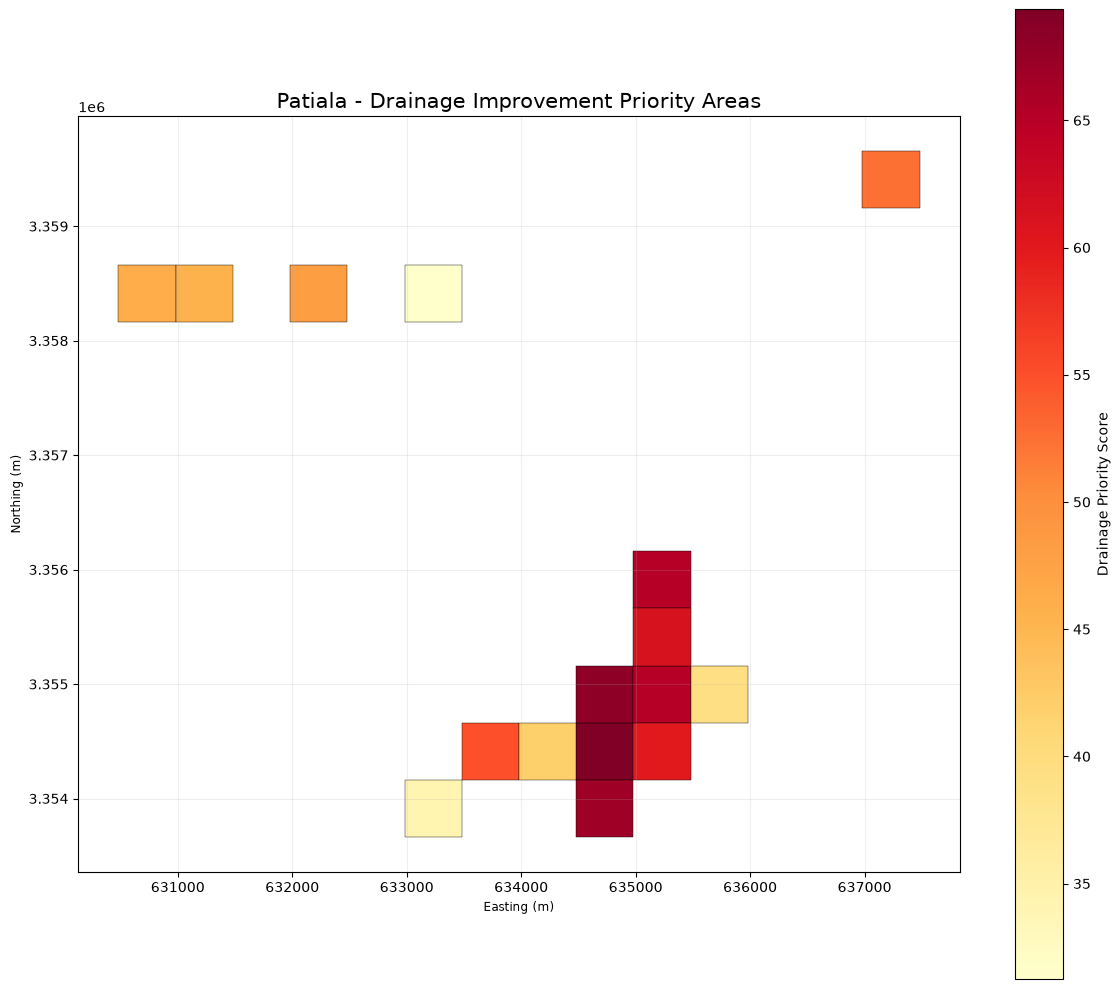

In [44]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(12, 10))

ranked_areas.plot(
    column="priority_score",
    cmap="YlOrRd",
    legend=True,
    edgecolor="black",
    linewidth=0.3,
    ax=ax,
    legend_kwds={"label": "Drainage Priority Score"}
)

ax.set_title(
    "Patiala - Drainage Improvement Priority Areas",
    fontsize=15
)

ax.set_xlabel("Easting (m)")
ax.set_ylabel("Northing (m)")
ax.grid(alpha=0.2)

plt.tight_layout()
plt.savefig(
    "../data/processed/drainage_priority_map.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

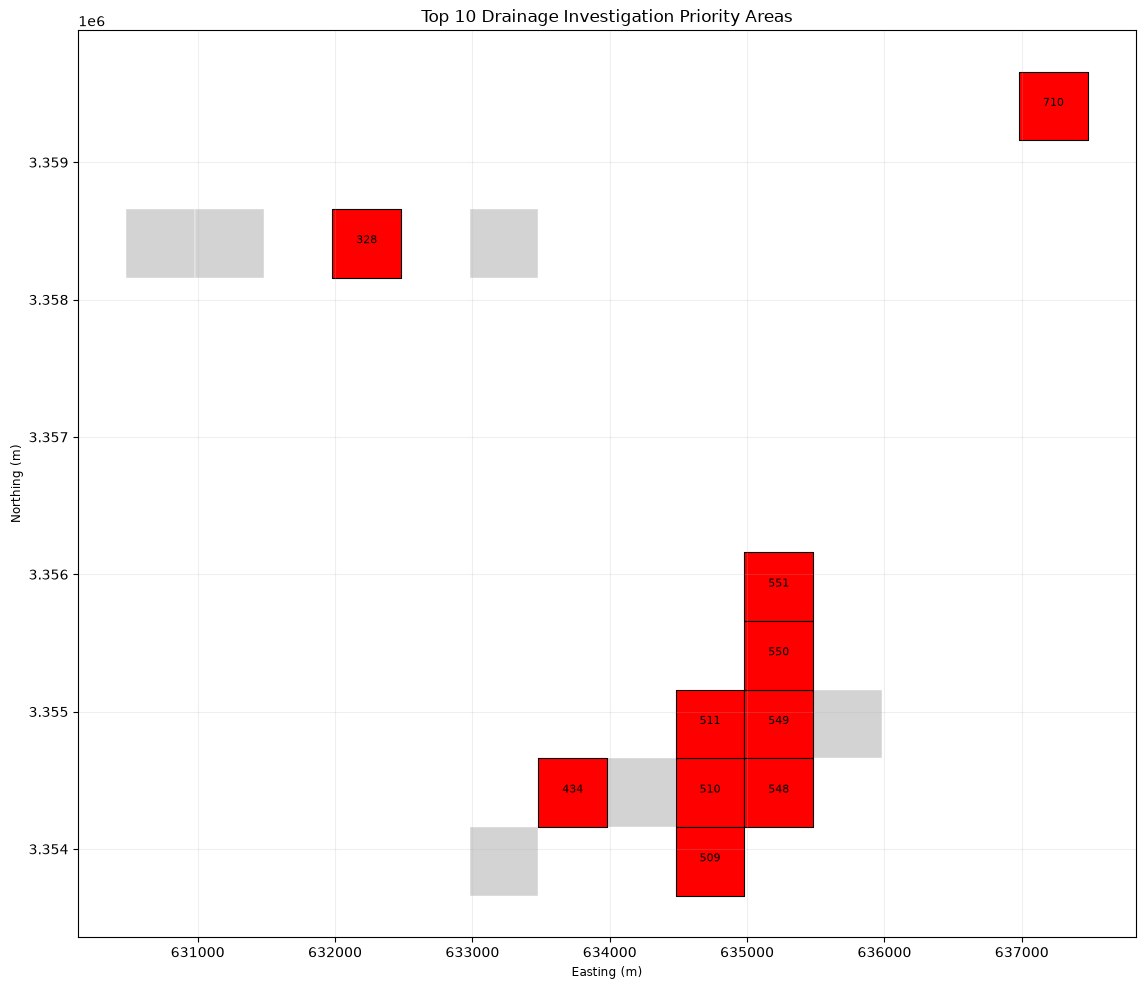

In [45]:
top_10 = ranked_areas.nlargest(10, "priority_score")

fig, ax = plt.subplots(figsize=(12, 10))

ranked_areas.plot(
    color="lightgrey",
    edgecolor="white",
    linewidth=0.3,
    ax=ax
)

top_10.plot(
    color="red",
    edgecolor="black",
    linewidth=0.8,
    ax=ax
)

for _, row in top_10.iterrows():
    point = row.geometry.centroid

    ax.annotate(
        str(int(row["grid_id"])),
        (point.x, point.y),
        fontsize=8,
        ha="center"
    )

ax.set_title("Top 10 Drainage Investigation Priority Areas")
ax.set_xlabel("Easting (m)")
ax.set_ylabel("Northing (m)")
ax.grid(alpha=0.2)

plt.tight_layout()
plt.savefig(
    "../data/processed/top_10_drainage_priority_map.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

In [46]:
print("FINAL DRAINAGE ANALYSIS SUMMARY")

print("\nTotal priority areas:", len(ranked_areas))

print("\nPriority level distribution:")
print(ranked_areas["priority_level"].value_counts())

print("\nTop 10 areas:")
display(
    ranked_areas[
        [
            "grid_id",
            "priority_score",
            "priority_level",
            "building_count",
            "road_length_m",
            "nearby_drainage_status"
        ]
    ].nlargest(10, "priority_score")
)

print("\nGenerated output files:")
print("1. final_drainage_improvement_recommendations.csv")
print("2. final_drainage_improvement_recommendations.geojson")
print("3. drainage_priority_map.png")
print("4. top_10_drainage_priority_map.png")

FINAL DRAINAGE ANALYSIS SUMMARY

Total priority areas: 16

Priority level distribution:
priority_level
High        13
Medium       3
Critical     0
Name: count, dtype: int64

Top 10 areas:


,grid_id,priority_score,priority_level,building_count,road_length_m,nearby_drainage_status
0,510,69.375,High,116.0,6888.375724,No mapped drain or ditch nearby
1,511,68.125,High,122.0,6531.288845,No mapped drain or ditch nearby
2,509,66.875,High,74.0,3834.135989,No mapped drain or ditch nearby
3,549,65.000,High,115.0,6480.824622,No mapped drain or ditch nearby
4,551,65.000,High,1.0,6922.148105,No mapped drain or ditch nearby
5,550,61.250,High,25.0,5292.737885,No mapped drain or ditch nearby
6,548,60.000,High,92.0,5100.878802,No mapped drain or ditch nearby
7,434,55.000,High,98.0,5060.023985,No mapped drain or ditch nearby
8,710,52.500,High,26.0,2264.472691,No mapped drain or ditch nearby
9,328,48.125,High,1.0,5210.609785,Mapped ditch nearby



Generated output files:
1. final_drainage_improvement_recommendations.csv
2. final_drainage_improvement_recommendations.geojson
3. drainage_priority_map.png
4. top_10_drainage_priority_map.png
